# Experiment: Grid cell size for the spatial split

Objective:
- **Question:** how far apart do two photos of the same land type need to be before being close together no longer makes them look more alike?
- **Why:** that distance becomes the grid square size for `split_v1.csv`. Squares at least this big keep look-alike neighbours in the same split, which stops spatial leakage.
- **Success criteria:** the similarity-vs-distance curve drops and then flattens, giving one clear distance to use as the square size.

No labels or training go into the fingerprints, so using every photo here (test included) doesn't leak answers.

## Cell 1: Setup

Finds the repo folder and the input files: Paddy's fingerprints in `data/fingerprints/` and the locations in `data/coords.csv`. Charts are saved to `figures/`.

Stops early with a clear message if any input file is missing.

In [1]:
from pathlib import Path

# repo root = first folder above this notebook that has data/coords.csv
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "coords.csv").exists())
FINGERPRINTS_DIR = ROOT / "data" / "fingerprints"
COORDS_CSV = ROOT / "data" / "coords.csv"
FIGURES = ROOT / "figures"

FIGURES.mkdir(exist_ok=True)
for f in [FINGERPRINTS_DIR / "fingerprints_view0.npy", FINGERPRINTS_DIR / "fingerprints_index.csv", COORDS_CSV]:
    assert f.exists(), f"missing {f}"
print("all input files found")

all input files found


## Cell 2: Parameters

Every setting the analysis uses, in one place. The seed makes the random pairs (and so every number below) identical on every run.

In [2]:
import numpy as np

SEED = 0                                 # random pairs in Cell 6
CLOSE_KM = 300                           # every same-label pair closer than this is measured exactly
BLOCK = 1000                             # photos per block in Cell 4; drop to 500 if you run out of memory
N_RANDOM_PAIRS = 4_000_000               # random pairs drawn for the background (~10% are same-label)
BAND_EDGES = np.geomspace(0.5, 4000, 31) # distance bands, evenly spaced on a log scale
MIN_PAIRS = 200                          # bands with fewer pairs are too noisy to plot
PLATEAU_KM = (50, 800)                   # flat stretch read off the chart, used to define "flat" in Results
FLAT_TOLERANCE = 0.005                   # a band counts as flat if within this of the plateau level
SAFETY_MARGIN = 1.25                     # round the cell size up, as the blockCV guide suggests

## Plan

- **Hypothesis:** photos of the same land type that are close together look more alike than ones far apart. The extra likeness fades with distance and then levels off.
- **Measure:** average cosine similarity of same-label photo pairs, grouped into distance bands (0.5 km → 4,000 km).
- **Reference level:** the background, i.e. the average similarity of random same-label pairs from anywhere in Europe.
- **Decision rule:** cell size = the start of the first band where the curve has come down to the flat stretch, × the safety margin.

## Cell 3: Load the fingerprints and match them to locations

The `.npy` has no names: row *i* belongs to row *i* of `fingerprints_index.csv`. We reorder `coords.csv` to that same order (never the other way round), so row *i* of every array below is the same photo.

**Checks:** row counts agree, names are unique, every photo has a location, labels agree in both files, and no fingerprint is broken (NaN or all zeros).

In [3]:
import pandas as pd

fingerprints = np.load(FINGERPRINTS_DIR / "fingerprints_view0.npy").astype(np.float32)  # float16 is too coarse for the maths
index = pd.read_csv(FINGERPRINTS_DIR / "fingerprints_index.csv")
coords = pd.read_csv(COORDS_CSV)

# the .npy and its index must line up row for row
assert len(fingerprints) == len(index), (len(fingerprints), len(index))
assert fingerprints.shape[1] == 768, fingerprints.shape

# "Forest/Forest_12" -> "Forest_12", the name coords.csv uses
index["filename"] = index["key"].str.split("/").str[-1]
assert index["filename"].is_unique, "duplicate names in the fingerprint index"
assert coords["filename"].is_unique, "duplicate names in coords.csv"

# reorder coords to the fingerprint order; reindex leaves NaN for any name coords.csv doesn't have
coords = coords.set_index("filename").reindex(index["filename"]).reset_index()
missing = coords["x3035"].isna()
assert not missing.any(), f"{missing.sum()} photos have no location, e.g. {coords.loc[missing, 'filename'].head(3).tolist()}"
assert (coords["label"] == index["label"]).all(), "labels disagree between the two files"

# a fingerprint of all zeros or NaNs would break the similarity maths
lengths = np.linalg.norm(fingerprints, axis=1)
assert np.isfinite(fingerprints).all(), "NaN or inf in fingerprints"
assert (lengths > 0).all(), f"{(lengths == 0).sum()} all-zero fingerprints"
fingerprints /= lengths[:, None]   # length 1, so a dot product = cosine similarity

xy_km = coords[["x3035", "y3035"]].to_numpy() / 1000   # EPSG:3035 metres -> km
labels = coords["label"].to_numpy()
label_ids = pd.factorize(labels)[0]
n = len(fingerprints)

print(f"{n:,} photos matched, {fingerprints.shape[1]} numbers each")
print(coords["label"].value_counts().sort_index().to_string())

27,000 photos matched, 768 numbers each
label
AnnualCrop              3000
Forest                  3000
HerbaceousVegetation    3000
Highway                 2500
Industrial              2500
Pasture                 2000
PermanentCrop           2500
Residential             3000
River                   2500
SeaLake                 3000


## Cell 4: Distances and similarities, 1,000 photos at a time

For each block of 1,000 photos we get the distance and similarity to **every** photo in one go (a matrix multiply), then keep only what we need:
- each photo's **nearest neighbour** distance (any label)
- every **same-label pair closer than 300 km**, with its distance and similarity

Working in blocks keeps memory at about 200 MB instead of the full 27,000 × 27,000 table (several GB).

In [4]:
nearest_km = np.empty(n, dtype=np.float32)
close_dist, close_sim = [], []

for start in range(0, n, BLOCK):
    rows = np.arange(start, min(start + BLOCK, n))
    dist = np.linalg.norm(xy_km[rows, None, :] - xy_km[None, :, :], axis=2).astype(np.float32)
    dist[np.arange(len(rows)), rows] = np.inf          # ignore each photo's distance to itself
    nearest_km[rows] = dist.min(axis=1)

    sim = fingerprints[rows] @ fingerprints.T          # cosine similarity to every photo
    # same label, under CLOSE_KM, and j > i so each pair is counted once
    keep = (label_ids[rows, None] == label_ids[None, :]) & (dist < CLOSE_KM) & (np.arange(n)[None, :] > rows[:, None])
    close_dist.append(dist[keep])
    close_sim.append(sim[keep])

close_dist = np.concatenate(close_dist)
close_sim = np.concatenate(close_sim)

print(f"same-label pairs under {CLOSE_KM} km: {len(close_dist):,}")
print(f"nearest-neighbour distance: median {np.median(nearest_km):.1f} km, "
      f"{(nearest_km < 1).mean():.0%} under 1 km, {(nearest_km < 5).mean():.0%} under 5 km")
print("photos sharing an exact location with another:", int((nearest_km == 0).sum()))

same-label pairs under 300 km: 5,314,924
nearest-neighbour distance: median 0.8 km, 59% under 1 km, 95% under 5 km
photos sharing an exact location with another: 0


## Cell 5: How spread out are the photos?

A histogram of each photo's distance to its nearest other photo. If most photos have a neighbour within a few km, a random split would put near-copies in both train and test, which is why the spatial split matters.

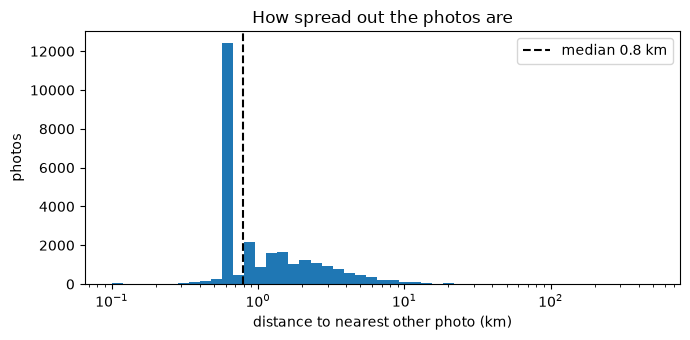

In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(np.clip(nearest_km, 0.1, None), bins=np.geomspace(0.1, 500, 50))  # clip 0 so it shows on a log axis
ax.set_xscale("log")
ax.axvline(np.median(nearest_km), color="k", ls="--", label=f"median {np.median(nearest_km):.1f} km")
ax.set(xlabel="distance to nearest other photo (km)", ylabel="photos", title="How spread out the photos are")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "nn_distance.png", dpi=150)
plt.show()

## Cell 6: Background level + average similarity per distance band

- **Background:** the average similarity of random same-label pairs from anywhere in Europe, i.e. how alike two photos of the same land type are when location doesn't matter.
- **Bands:** pairs are grouped by distance (log-spaced, 0.5 km → 4,000 km) and averaged. Bands under 300 km use every pair from Cell 4, and bands beyond use the random pairs.
- **err** = 2 standard errors. Bands with fewer than 200 pairs are dropped as too noisy.

In [6]:
rng = np.random.default_rng(SEED)
i, j = rng.integers(0, n, size=(2, N_RANDOM_PAIRS))
same = (label_ids[i] == label_ids[j]) & (i != j)
i, j = i[same], j[same]
rand_dist = np.linalg.norm(xy_km[i] - xy_km[j], axis=1)
rand_sim = np.einsum("ij,ij->i", fingerprints[i], fingerprints[j])   # row-by-row dot product
background = rand_sim.mean()
print(f"background (random same-label pairs, n={len(rand_sim):,}): {background:.3f}")

far = rand_dist >= CLOSE_KM
pair_dist = np.concatenate([close_dist, rand_dist[far]])
pair_sim = np.concatenate([close_sim, rand_sim[far]])

band = np.digitize(pair_dist, BAND_EDGES) - 1   # pairs under 0.5 km get -1 and are left out
rows = []
for b in range(len(BAND_EDGES) - 1):
    s = pair_sim[band == b]
    if len(s) >= MIN_PAIRS:
        lo, hi = BAND_EDGES[b], BAND_EDGES[b + 1]
        rows.append({"from_km": lo, "to_km": hi, "mid_km": np.sqrt(lo * hi),
                     "pairs": len(s), "similarity": s.mean(), "err": 2 * s.std() / np.sqrt(len(s))})  # err = 2 standard errors
bands = pd.DataFrame(rows)
bands.round(3)

background (random same-label pairs, n=405,461): 0.418


,from_km,to_km,mid_km,pairs,similarity,err
0,0.500,0.675,0.581,11522,0.621,0.004
1,0.675,0.910,0.784,928,0.563,0.011
2,0.910,1.228,1.057,9147,0.603,0.004
3,1.228,1.657,1.427,19152,0.589,0.003
4,1.657,2.236,1.925,20142,0.572,0.003
5,2.236,3.017,2.597,30415,0.559,0.002
6,3.017,4.071,3.505,40537,0.544,0.002
7,4.071,5.493,4.729,58887,0.534,0.002
8,5.493,7.411,6.380,81375,0.523,0.001
9,7.411,10.000,8.609,107917,0.510,0.001


## Cell 7: The chart

Do nearby photos of the same land type look more alike? Where the curve comes down and **flattens** is where location stops mattering. That distance is the grid square size.

The dotted line at 300 km marks where the data switches from every pair (left) to the random sample (right).

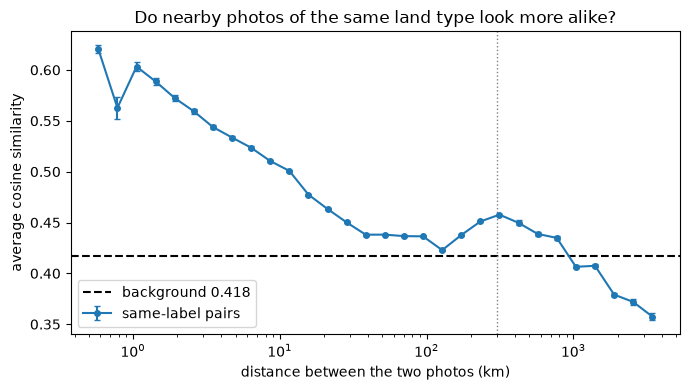

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(bands["mid_km"], bands["similarity"], yerr=bands["err"], marker="o", ms=4, capsize=2, label="same-label pairs")
ax.axhline(background, color="k", ls="--", label=f"background {background:.3f}")
ax.axvline(CLOSE_KM, color="grey", ls=":", lw=1)   # left: every pair, right: random sample
ax.set_xscale("log")
ax.set(xlabel="distance between the two photos (km)", ylabel="average cosine similarity",
       title="Do nearby photos of the same land type look more alike?")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "similarity_vs_distance.png", dpi=150)
plt.show()

## Results

The key numbers in one small table, using the decision rule from the Plan:
- **plateau** = average similarity across the flat stretch (`PLATEAU_KM`)
- **flattens_at_km** = start of the first band within `FLAT_TOLERANCE` of the plateau
- **suggested_cell_km** = that distance × `SAFETY_MARGIN`

In [8]:
on_plateau = bands["mid_km"].between(*PLATEAU_KM)
assert on_plateau.sum() >= 3, "too few bands in PLATEAU_KM to define a flat level"
plateau = bands.loc[on_plateau, "similarity"].mean()

flat = bands["similarity"] <= plateau + FLAT_TOLERANCE
assert flat.any(), "the curve never comes down to the plateau"
flattens_at_km = bands.loc[flat, "from_km"].iloc[0]   # bands are sorted by distance, so the first flat one

result = {
    "seed": SEED,
    "nearest_neighbour_median_km": round(float(np.median(nearest_km)), 2),
    "similarity_under_1km": round(float(bands["similarity"].iloc[0]), 3),
    "background": round(float(background), 3),
    "plateau": round(float(plateau), 3),
    "flattens_at_km": round(float(flattens_at_km), 1),
    "suggested_cell_km": round(float(flattens_at_km * SAFETY_MARGIN)),
}
result

{'seed': 0,
 'nearest_neighbour_median_km': 0.79,
 'similarity_under_1km': 0.621,
 'background': 0.418,
 'plateau': 0.44,
 'flattens_at_km': 33.1,
 'suggested_cell_km': 41}